# Day 27 — Oscillators, written by hand

**Acceptance:** the hand-written RSI matches a reference implementation to four decimal places.

The reference is **TA-Lib** (C library 0.6.4, Python wrapper 0.6.8), which finmgr does not depend on.
Its output on a 400-bar synthetic OHLC series was frozen into
`tests/fixtures/oscillators/talib_reference.csv` by `tools/oscillator_reference.py`. Check 1 reads that file.
Check 2 runs the same comparison on real AAPL closes. If `talib` is importable in this kernel,
it is called live. Otherwise the reference is Wilder's RSI rebuilt from pandas' `ewm(alpha=1/14)`,
which shares no code with the module.

Checks 3 and 4 cover what each oscillator *means* on AAPL, and the chart is saved to
`docs/day27_oscillators_AAPL.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from finmgr.features.oscillators import macd, percent_b, read_oscillators, rsi, stochastic

TICKER = "AAPL"
AS_OF = "2026-10-14"
START = "2025-10-01"
osc = read_oscillators(TICKER, as_of=AS_OF).set_index("date")
print(len(osc), "bars,", osc.index.min(), "to", osc.index.max())

4221 bars, 2010-01-04 to 2026-10-14


## Check 1 — RSI(14) against TA-Lib, to four decimal places

In [2]:
ref = pd.read_csv("tests/fixtures/oscillators/talib_reference.csv", comment="#")
mine = rsi(ref["close"], 14)
defined = ref["rsi_14"].notna()
assert (mine.isna() == ref["rsi_14"].isna()).all()
diff = (mine[defined] - ref["rsi_14"][defined]).abs()
same_4dp = (mine[defined].round(4) == ref["rsi_14"][defined].round(4)).all()
print(f"{defined.sum()} values, RSI range {ref['rsi_14'].min():.2f}..{ref['rsi_14'].max():.2f}")
print(f"max |mine - TA-Lib| = {diff.max():.2e}; identical to 4 dp: {same_4dp}")
assert same_4dp and diff.max() < 1e-9
print(
    pd.DataFrame({"close": ref["close"], "TA-Lib": ref["rsi_14"], "finmgr": mine})
    .iloc[12:20]
    .round(6)
)
# The other three, against the same file (MACD after TA-Lib's different seed has decayed):
checks = {
    "stoch_d": (stochastic(ref["high"], ref["low"], ref["close"])["stoch_d"], 0),
    "bb_pctb": (percent_b(ref["close"]), 0),
    "macd_hist": (macd(ref["close"])["macd_hist"], 120),
}
for col, (series, skip) in checks.items():
    both = ref[col].notna() & series.notna() & (ref.index >= skip)
    print(f"{col:10s} max |diff| {np.abs(series[both] - ref[col][both]).max():.1e}")

386 values, RSI range 13.00..85.76
max |mine - TA-Lib| = 1.42e-14; identical to 4 dp: True
      close     TA-Lib     finmgr
12  97.8943        NaN        NaN
13  97.7101        NaN        NaN
14  98.3251  39.208913  39.208913
15  95.2160  32.661805  32.661805
16  95.2653  32.853269  32.853269
17  95.6593  34.457194  34.457194
18  95.9369  35.623980  35.623980
19  94.1548  31.720088  31.720088
stoch_d    max |diff| 8.5e-14
bb_pctb    max |diff| 1.2e-08
macd_hist  max |diff| 1.6e-07


## Check 2 — the same on AAPL's real closes

In [3]:
closes = osc["adj_close"]
try:
    import talib

    reference = pd.Series(talib.RSI(closes.to_numpy(), 14), index=closes.index)
    source = f"TA-Lib {talib.__version__} (live)"
except ImportError:
    change = closes.diff()
    up, down = change.clip(lower=0), (-change).clip(lower=0)

    def seeded(x: pd.Series) -> pd.Series:
        return pd.concat([pd.Series([x.iloc[1:15].mean()]), x.iloc[15:].reset_index(drop=True)])

    au = seeded(up).ewm(alpha=1 / 14, adjust=False).mean().to_numpy()
    ad = seeded(down).ewm(alpha=1 / 14, adjust=False).mean().to_numpy()
    reference = pd.Series(np.r_[[np.nan] * 14, 100 - 100 / (1 + au / ad)], index=closes.index)
    source = "pandas ewm(alpha=1/14), Wilder-seeded"
both = reference.notna()
assert (osc["rsi_14"].notna() == both).all()  # AAPL has no gap in the store
gap = (osc["rsi_14"][both] - reference[both]).abs().max()
print(f"{both.sum()} AAPL values vs {source}: max |diff| = {gap:.2e}")
assert (osc["rsi_14"][both].round(4) == reference[both].round(4)).all()
print("RSI MATCHES TO 4 DP")

4207 AAPL values vs pandas ewm(alpha=1/14), Wilder-seeded: max |diff| = 4.26e-14
RSI MATCHES TO 4 DP


## Check 3 — the oscillators mean what they say

* RSI is above 70 only after a run of up days, and below 30 only after a run of down days. The 14-session return should agree in sign.
* MACD is positive exactly when the 12-session EMA is above the 26-session EMA.
* `stoch_k` is 100 on a 14-session closing high and 0 on a closing low (approximately, since the high and low are intraday).
* `bb_pctb` is above 1 only when the close is above the upper band, i.e. its 20-session z-score is above 2.

In [4]:
ret14 = osc["adj_close"] / osc["adj_close"].shift(14) - 1
hot, cold = osc["rsi_14"] > 70, osc["rsi_14"] < 30
print(f"RSI>70 on {hot.sum()} bars, 14d return >0 on {(ret14[hot] > 0).mean():.0%} of them")
print(f"RSI<30 on {cold.sum()} bars, 14d return <0 on {(ret14[cold] < 0).mean():.0%} of them")
assert (ret14[hot] > 0).mean() > 0.95 and (ret14[cold] < 0).mean() > 0.95
k_hot, k_cold = osc.loc[hot, "stoch_k"].median(), osc.loc[cold, "stoch_k"].median()
print(f"stoch_k on RSI>70 bars: median {k_hot:.0f}; on RSI<30: {k_cold:.0f}")
assert k_hot > 70 > 30 > k_cold
c = osc["adj_close"]
z = (c - c.rolling(20).mean()) / c.rolling(20).std(ddof=0)
assert np.allclose(osc["bb_pctb"].dropna(), (0.5 + z / 4).dropna())
pctb = osc["bb_pctb"]
print(f"%B>1 on {(pctb > 1).sum()} bars, %B<0 on {(pctb < 0).sum()} of {pctb.notna().sum()}")
print(osc[["rsi_14", "macd_hist_pct", "stoch_k", "stoch_d", "bb_pctb"]].describe().round(3))

RSI>70 on 596 bars, 14d return >0 on 100% of them
RSI<30 on 91 bars, 14d return <0 on 100% of them
stoch_k on RSI>70 bars: median 94; on RSI<30: 6
%B>1 on 337 bars, %B<0 on 184 of 4202
         rsi_14  macd_hist_pct   stoch_k   stoch_d   bb_pctb
count  4207.000       4188.000  4208.000  4206.000  4202.000
mean     55.329          0.000    59.712    59.720     0.588
std      13.005          0.006    30.836    28.895     0.332
min      17.910         -0.025     0.000     0.587    -0.327
25%      45.616         -0.003    32.108    33.493     0.317
50%      55.285          0.000    66.704    66.429     0.647
75%      64.909          0.004    88.107    86.135     0.857
max      90.695          0.022   100.000    99.768     1.393


## Check 4 — ranges

In [5]:
assert osc["rsi_14"].between(0, 100).all() or osc["rsi_14"].dropna().between(0, 100).all()
assert osc[["stoch_k", "stoch_d"]].dropna().apply(lambda s: s.between(0, 100)).all().all()
assert osc.iloc[40:].notna().all().all()
print("RSI and stochastic in [0, 100]; every column defined after the 34-bar warm-up")

RSI and stochastic in [0, 100]; every column defined after the 34-bar warm-up


## The chart

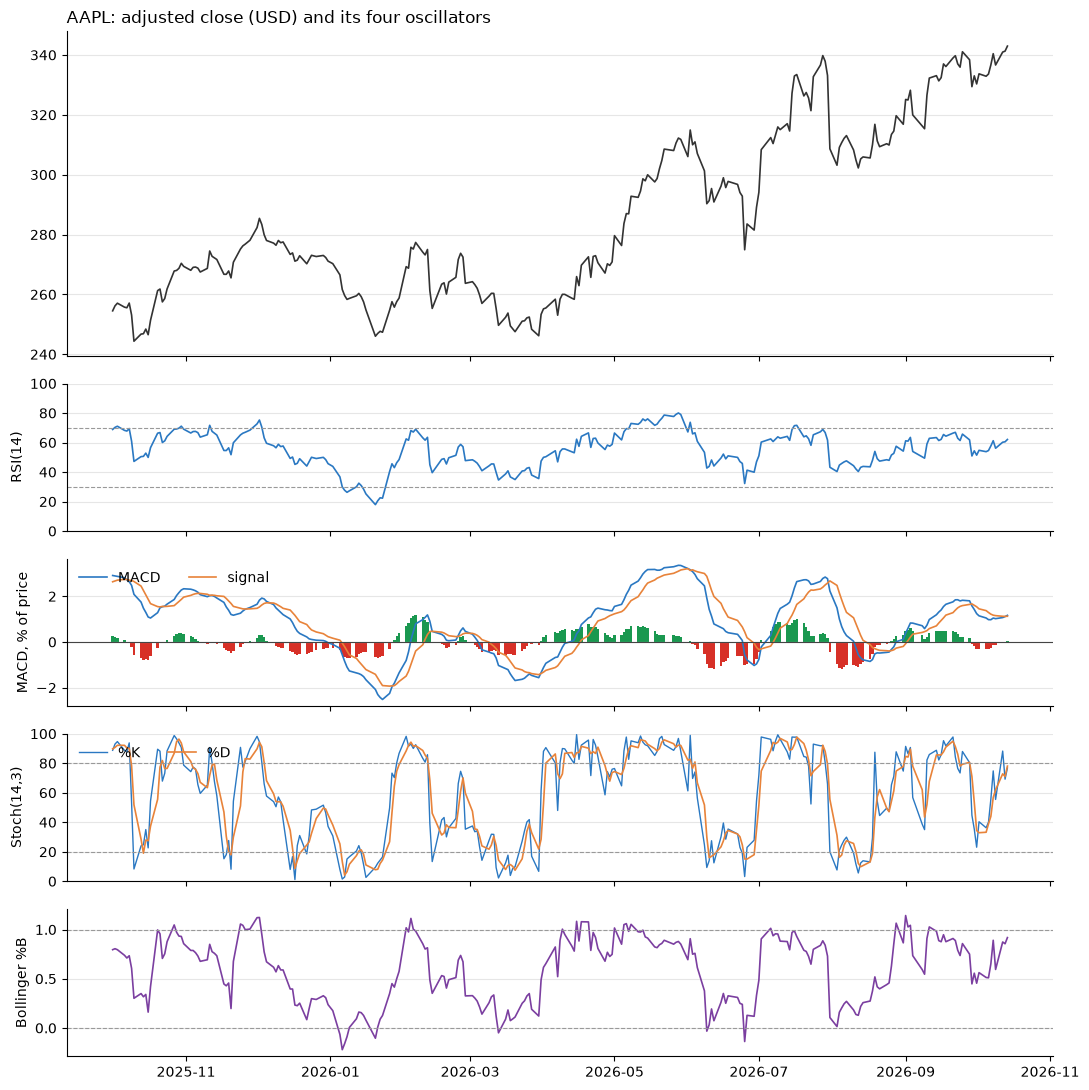

In [6]:
view = osc.loc[pd.Timestamp(START).date() :]
d = pd.to_datetime(view.index)
fig, axes = plt.subplots(
    5, 1, figsize=(11, 11), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1, 1, 1]}
)
price, r, m, s, b = axes
price.plot(d, view["adj_close"], color="#333", lw=1.2)
price.set_title(f"{TICKER}: adjusted close (USD) and its four oscillators", loc="left")
r.plot(d, view["rsi_14"], color="#2a78c2", lw=1.2)
for y in (30, 70):
    r.axhline(y, color="#999", lw=0.8, ls="--")
r.set_ylabel("RSI(14)")
r.set_ylim(0, 100)
m.plot(d, 100 * view["macd_pct"], color="#2a78c2", lw=1.2, label="MACD")
m.plot(d, 100 * view["macd_signal_pct"], color="#e8833a", lw=1.2, label="signal")
bar_colors = np.where(view["macd_hist_pct"] > 0, "#1a9850", "#d73027")
m.bar(d, 100 * view["macd_hist_pct"], color=bar_colors, width=1.0)
m.axhline(0, color="#444", lw=0.8)
m.set_ylabel("MACD, % of price")
m.legend(loc="upper left", frameon=False, ncol=2)
s.plot(d, view["stoch_k"], color="#2a78c2", lw=1.0, label="%K")
s.plot(d, view["stoch_d"], color="#e8833a", lw=1.2, label="%D")
for y in (20, 80):
    s.axhline(y, color="#999", lw=0.8, ls="--")
s.set_ylabel("Stoch(14,3)")
s.set_ylim(0, 100)
s.legend(loc="upper left", frameon=False, ncol=2)
b.plot(d, view["bb_pctb"], color="#7b3fa0", lw=1.2)
for y in (0, 1):
    b.axhline(y, color="#999", lw=0.8, ls="--")
b.set_ylabel("Bollinger %B")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e6e6", lw=0.8)
fig.tight_layout()
fig.savefig("docs/day27_oscillators_AAPL.png", dpi=110)
plt.show()